# ☕ The Tale of Two Coffee Shops
## *Learning Core ML Concepts Through a Real Business Problem*

---

### The Story

You've just been hired as the **first data scientist** at *BeanScene*, a growing coffee chain in Bangalore. The CEO, Priya, walks into your office on Day 1 and says:

> *"We have two shops — one in Koramangala and one in Indiranagar. I have budget to expand only ONE of them into a flagship store. I need you to look at the data and tell me: **which shop should we bet on?**"*

She hands you a USB drive with 6 months of daily sales data and walks out.

**Your mission:** Use data to make this decision. Along the way, you'll discover *why* concepts like mean, variance, and standard deviation aren't just textbook formulas — they're the **lenses** through which we see patterns in data.

---

Let's begin. 👇

In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Ellipse
import warnings
warnings.filterwarnings('ignore')

# Make plots look clean
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 12
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
sns.set_palette("husl")

print("✅ All set! Let's explore BeanScene's data.")

✅ All set! Let's explore BeanScene's data.


## Chapter 1: First Look at the Data

Let's load up the sales data Priya gave us. Each row is one day, and we have several measurements per day for each shop.

In [30]:
df = pd.read_csv('bean_scene_data.csv')

## Chapter 2: The "Typical" Day — Understanding the Mean (μ)

### The Business Question
Priya's first question is simple: *"On a typical day, which shop makes more money?"*

This is exactly what the **mean** answers. It tells us: *if we had to summarize all 180 days with a single number, what would that number be?*

### The Intuition (Before Any Formula)
Imagine you piled all 180 daily revenue numbers onto a see-saw (a balance beam). **The mean is the point where the see-saw perfectly balances.** It's the center of gravity of your data.

In [31]:
# Let's compute the mean revenue for each shop — the "typical" day
mean_revenue = df.groupby('shop')['daily_revenue_inr'].mean()

print("=" * 50)
print("  AVERAGE DAILY REVENUE")
print("=" * 50)
for shop, val in mean_revenue.items():
    print(f"  {shop:15s}:  ₹{val:,.0f}")
print("=" * 50)
print(f"\n  Difference: ₹{mean_revenue['Indiranagar'] - mean_revenue['Koramangala']:,.0f}/day")
print(f"\n💡 On a 'typical' day, Indiranagar earns about ₹{mean_revenue['Indiranagar'] - mean_revenue['Koramangala']:,.0f} more.")
print("   Case closed? Should we just pick Indiranagar?")
print("   ...not so fast. Let's dig deeper.")

  AVERAGE DAILY REVENUE
  Indiranagar    :  ₹31,191
  Koramangala    :  ₹27,934

  Difference: ₹3,257/day

💡 On a 'typical' day, Indiranagar earns about ₹3,257 more.
   Case closed? Should we just pick Indiranagar?
   ...not so fast. Let's dig deeper.


### Visualizing the Mean

Let's actually *see* what the mean looks like on real data. The dashed line below is the mean — the "balancing point" of all the dots.

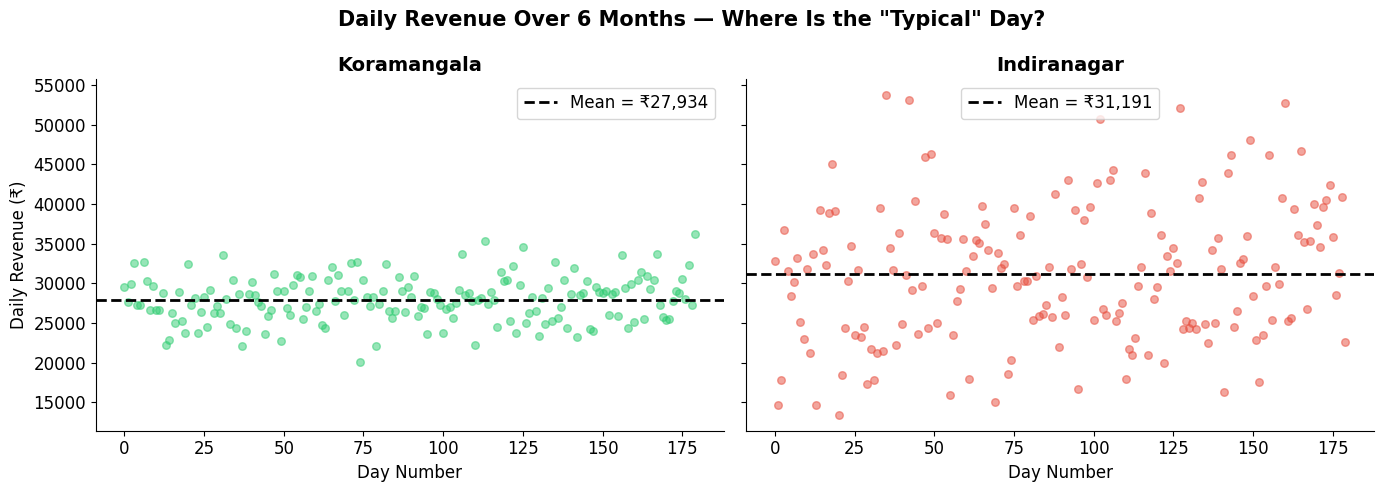


👀 Notice anything? The means are close... but the SPREAD is very different!
   Koramangala's dots cluster tightly. Indiranagar's dots are all over the place.
   The mean alone is hiding something important.


In [32]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

# Koramangala
k_data = df[df['shop'] == 'Koramangala']['daily_revenue_inr']
k_mean = k_data.mean()
ax1.scatter(range(len(k_data)), k_data, alpha=0.5, s=30, color='#2ecc71')
ax1.axhline(k_mean, color='black', linestyle='--', linewidth=2, label=f'Mean = ₹{k_mean:,.0f}')
ax1.set_title('Koramangala', fontsize=14, fontweight='bold')
ax1.set_xlabel('Day Number')
ax1.set_ylabel('Daily Revenue (₹)')
ax1.legend()

# Indiranagar
i_data = df[df['shop'] == 'Indiranagar']['daily_revenue_inr']
i_mean = i_data.mean()
ax2.scatter(range(len(i_data)), i_data, alpha=0.5, s=30, color='#e74c3c')
ax2.axhline(i_mean, color='black', linestyle='--', linewidth=2, label=f'Mean = ₹{i_mean:,.0f}')
ax2.set_title('Indiranagar', fontsize=14, fontweight='bold')
ax2.set_xlabel('Day Number')
ax2.legend()

plt.suptitle('Daily Revenue Over 6 Months — Where Is the "Typical" Day?', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n👀 Notice anything? The means are close... but the SPREAD is very different!")
print("   Koramangala's dots cluster tightly. Indiranagar's dots are all over the place.")
print("   The mean alone is hiding something important.")

### The Mean — One Per Dimension

Here's an important idea: **the mean is calculated separately for each feature (dimension)**. Each shop doesn't have *one* mean — it has a mean for revenue, a mean for customers, a mean for wait time, etc.

Think of the mean as a **"typical day profile"** — a summary across every dimension of the data.

In [33]:
# Mean across all features — the "profile" of a typical day
features = ['daily_revenue_inr', 'customers', 'avg_order_value', 'avg_wait_time_min']
mean_profile = df.groupby('shop')[features].mean().round(1)

print("📊 'Typical Day' Profile for Each Shop")
print("=" * 65)
display(mean_profile.style.format({
    'daily_revenue_inr': '₹{:,.0f}',
    'customers': '{:.0f}',
    'avg_order_value': '₹{:.1f}',
    'avg_wait_time_min': '{:.1f} min'
}).set_properties(**{'text-align': 'center'}))
print("\n🔑 Key Takeaway: The mean gives us a MULTI-DIMENSIONAL summary.")
print("   A 'typical day' at Koramangala looks like:")
k = mean_profile.loc['Koramangala']
print(f"   → ₹{k['daily_revenue_inr']:,.0f} revenue, {k['customers']:.0f} customers, "
      f"₹{k['avg_order_value']:.0f} avg order, {k['avg_wait_time_min']:.1f} min wait")

📊 'Typical Day' Profile for Each Shop


,daily_revenue_inr,customers,avg_order_value,avg_wait_time_min
shop,,,,
Indiranagar,"₹31,191",159,₹192.7,6.2 min
Koramangala,"₹27,934",150,₹184.4,6.5 min



🔑 Key Takeaway: The mean gives us a MULTI-DIMENSIONAL summary.
   A 'typical day' at Koramangala looks like:
   → ₹27,934 revenue, 150 customers, ₹184 avg order, 6.5 min wait


## Chapter 3: When the Mean Lies — Why We Need Variance

### The Danger of Averages

Here's a famous joke in statistics:

> *"A statistician drowned crossing a river that was, on average, 3 feet deep."*

The mean tells you the center, but it says **nothing about the spread**. Two datasets can have the exact same mean but tell completely different stories.

Let's see this in action with our coffee shops.

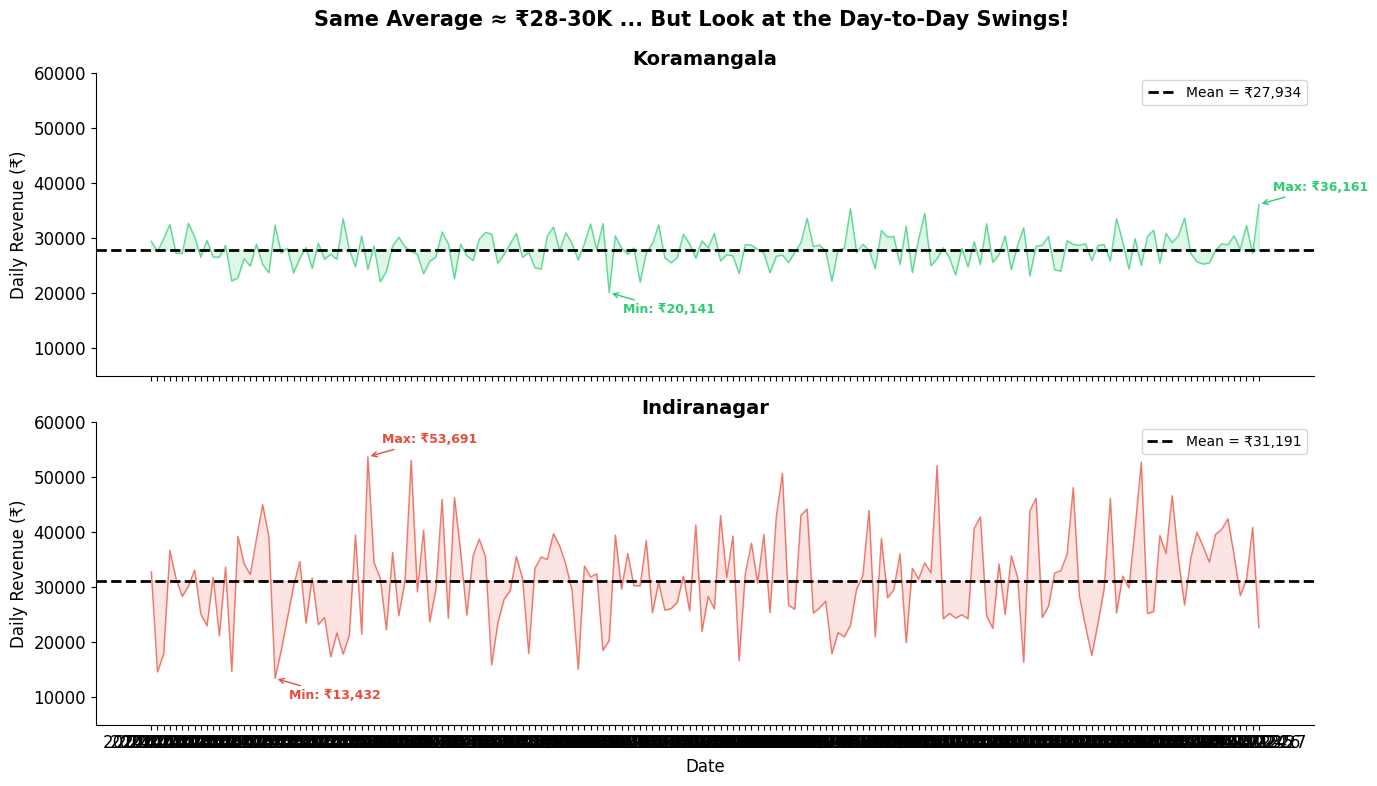


📊 Revenue ranges:
   Koramangala:  ₹20,141  →  ₹36,161  (range: ₹16,020)
   Indiranagar:  ₹13,432  →  ₹53,691  (range: ₹40,259)

⚠️  Indiranagar has days with ₹53,691 (amazing!) but also ₹13,432 (ouch!).
   The mean hid all this drama. We need a way to MEASURE the spread.


In [34]:
# A dramatic visual: same-ish mean, VERY different stories

# Side-by-side line plot showing daily revenue over time
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True, sharey=True)

for ax, shop, color in zip(axes, ['Koramangala', 'Indiranagar'], ['#2ecc71', '#e74c3c']):
    data = df[df['shop'] == shop]
    mean_val = data['daily_revenue_inr'].mean()

    ax.plot(data['date'], data['daily_revenue_inr'], color=color, alpha=0.7, linewidth=1)
    ax.fill_between(data['date'], data['daily_revenue_inr'], mean_val, color=color, alpha=0.15)
    ax.axhline(mean_val, color='black', linestyle='--', linewidth=2, label=f'Mean = ₹{mean_val:,.0f}')
    ax.set_title(f'{shop}', fontsize=14, fontweight='bold')
    ax.set_ylabel('Daily Revenue (₹)')
    ax.legend(fontsize=10, loc='upper right')
    ax.set_ylim(5000, 60000)

    # Annotate min and max
    rev = data['daily_revenue_inr']
    ax.annotate(f'Max: ₹{rev.max():,.0f}', xy=(data['date'].iloc[rev.argmax()], rev.max()),
                fontsize=9, fontweight='bold', color=color,
                xytext=(10, 10), textcoords='offset points',
                arrowprops=dict(arrowstyle='->', color=color))
    ax.annotate(f'Min: ₹{rev.min():,.0f}', xy=(data['date'].iloc[rev.argmin()], rev.min()),
                fontsize=9, fontweight='bold', color=color,
                xytext=(10, -15), textcoords='offset points',
                arrowprops=dict(arrowstyle='->', color=color))

axes[1].set_xlabel('Date')
fig.suptitle('Same Average ≈ ₹28-30K ... But Look at the Day-to-Day Swings!',
             fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

k_data = df[df['shop']=='Koramangala']['daily_revenue_inr']
i_data = df[df['shop']=='Indiranagar']['daily_revenue_inr']

print(f"\n📊 Revenue ranges:")
print(f"   Koramangala:  ₹{k_data.min():,.0f}  →  ₹{k_data.max():,.0f}  (range: ₹{k_data.max()-k_data.min():,.0f})")
print(f"   Indiranagar:  ₹{i_data.min():,.0f}  →  ₹{i_data.max():,.0f}  (range: ₹{i_data.max()-i_data.min():,.0f})")
print(f"\n⚠️  Indiranagar has days with ₹{i_data.max():,.0f} (amazing!) but also ₹{i_data.min():,.0f} (ouch!).")
print("   The mean hid all this drama. We need a way to MEASURE the spread.")

## Chapter 4: Measuring the Spread — Variance (σ²)

### Building the Intuition Step by Step

We need a single number that captures *"how spread out is this data?"* Let's build it from scratch, thinking like a detective.

**Step 1: How far is each point from the mean?**

For each day's revenue, we ask: *"How far was this from the typical day?"*

This gives us the **deviation**: `xᵢ - μ`

In [35]:
# Let's trace through this with REAL data from Koramangala (first 10 days)
k_revenue = df[df['shop']=='Koramangala']['daily_revenue_inr'].values
mean_k = k_revenue.mean()

print(f"Mean daily revenue (Koramangala): ₹{mean_k:,.0f}")
print(f"\n{'Day':>5} {'Revenue':>12} {'Deviation (xᵢ - μ)':>22}  Interpretation")
print("-" * 70)
for i in range(10):
    dev = k_revenue[i] - mean_k
    direction = "above avg ↑" if dev > 0 else "below avg ↓"
    print(f"{i+1:>5} {k_revenue[i]:>12,.0f} {dev:>+18,.0f}      {direction}")

total_dev = sum(k_revenue[:10] - mean_k)
print(f"\n  Sum of deviations (these 10 days): {total_dev:+,.0f}")
print(f"\n🤔 Problem: Some deviations are positive, some negative.")
print("   They tend to cancel out! The sum is close to zero.")
print("   (Over ALL 180 days, the sum would be EXACTLY zero — that's a property of the mean.)")
print("\n   We need to get rid of the negative signs somehow...")

Mean daily revenue (Koramangala): ₹27,934

  Day      Revenue     Deviation (xᵢ - μ)  Interpretation
----------------------------------------------------------------------
    1       29,490             +1,556      above avg ↑
    2       27,585               -349      below avg ↓
    3       29,943             +2,009      above avg ↑
    4       32,569             +4,635      above avg ↑
    5       27,298               -636      below avg ↓
    6       27,298               -636      below avg ↓
    7       32,738             +4,804      above avg ↑
    8       30,302             +2,368      above avg ↑
    9       26,592             -1,342      below avg ↓
   10       29,628             +1,694      above avg ↑

  Sum of deviations (these 10 days): +14,107

🤔 Problem: Some deviations are positive, some negative.
   They tend to cancel out! The sum is close to zero.
   (Over ALL 180 days, the sum would be EXACTLY zero — that's a property of the mean.)

   We need to get rid of the nega

**Step 2: Square the deviations (to eliminate negatives)**

Why square instead of absolute value? Squaring **punishes big deviations more** — a day that's ₹10,000 off is treated as much worse than two days that are ₹5,000 off. This is exactly the behavior we want in ML — outliers matter!

In [36]:
print(f"{'Day':>5} {'Revenue':>12} {'Deviation':>14} {'Squared Deviation':>20}")
print("-" * 60)
for i in range(10):
    dev = k_revenue[i] - mean_k
    sq_dev = dev ** 2
    print(f"{i+1:>5} {k_revenue[i]:>12,.0f} {dev:>+14,.0f} {sq_dev:>20,.0f}")

print(f"\n✅ All positive now! Big deviations become REALLY big (that's intentional).")
print(f"\n   Example: A deviation of ₹6,000 → squared = 36,000,000")
print(f"           A deviation of ₹1,000 → squared =  1,000,000")
print(f"           The big one is 36x larger, not just 6x. Squaring amplifies outliers.")

  Day      Revenue      Deviation    Squared Deviation
------------------------------------------------------------
    1       29,490         +1,556            2,422,381
    2       27,585           -349              121,522
    3       29,943         +2,009            4,037,688
    4       32,569         +4,635           21,486,933
    5       27,298           -636              403,987
    6       27,298           -636              403,987
    7       32,738         +4,804           23,082,259
    8       30,302         +2,368            5,609,319
    9       26,592         -1,342            1,799,891
   10       29,628         +1,694            2,870,991

✅ All positive now! Big deviations become REALLY big (that's intentional).

   Example: A deviation of ₹6,000 → squared = 36,000,000
           A deviation of ₹1,000 → squared =  1,000,000
           The big one is 36x larger, not just 6x. Squaring amplifies outliers.


**Step 3: Average the squared deviations → That's the Variance!**

The variance is simply the *average of all squared deviations*. It answers: *"On average, how much does each data point deviate from the mean (in squared units)?"*

In [37]:
# Compute variance for both shops
k_rev = df[df['shop']=='Koramangala']['daily_revenue_inr']
i_rev = df[df['shop']=='Indiranagar']['daily_revenue_inr']

# Step by step for Koramangala
deviations_k = k_rev - k_rev.mean()
squared_devs_k = deviations_k ** 2
variance_k = squared_devs_k.mean()

# And Indiranagar
deviations_i = i_rev - i_rev.mean()
squared_devs_i = deviations_i ** 2
variance_i = squared_devs_i.mean()

print("VARIANCE OF DAILY REVENUE")
print("=" * 55)
print(f"  Koramangala:  {variance_k:>18,.0f}  (₹²)")
print(f"  Indiranagar:  {variance_i:>18,.0f}  (₹²)")
print("=" * 55)
print(f"\n  Indiranagar's variance is {variance_i/variance_k:.1f}x larger!")
print(f"\n🤔 But wait... the units are '₹ squared'. What does ₹² even mean?")
print("   That's... not very interpretable. We need to fix this.")

VARIANCE OF DAILY REVENUE
  Koramangala:           8,080,174  (₹²)
  Indiranagar:          73,169,986  (₹²)

  Indiranagar's variance is 9.1x larger!

🤔 But wait... the units are '₹ squared'. What does ₹² even mean?
   That's... not very interpretable. We need to fix this.


## Chapter 5: Back to Human Units — Standard Deviation (σ)

The variance gave us a number in *squared units* (₹²), which is hard to interpret. The fix is simple: **take the square root** to get back to the original units.

This gives us the **Standard Deviation (σ)** — arguably the most useful single number in all of data science.

In [38]:
std_k = np.sqrt(variance_k)  # or equivalently: k_rev.std()
std_i = np.sqrt(variance_i)

print("STANDARD DEVIATION OF DAILY REVENUE")
print("=" * 55)
print(f"  Koramangala:  ₹{std_k:>10,.0f}")
print(f"  Indiranagar:  ₹{std_i:>10,.0f}")
print("=" * 55)

print(f"\n📖 How to read this:")
print(f"   Koramangala: On a typical day, revenue deviates by about ±₹{std_k:,.0f} from the mean.")
print(f"   Indiranagar: On a typical day, revenue deviates by about ±₹{std_i:,.0f} from the mean.")
print(f"\n   That's a HUGE difference in consistency!")
print(f"   Indiranagar swings ±₹{std_i:,.0f} per day — that's {std_i/std_k:.1f}x more volatile than Koramangala.")

STANDARD DEVIATION OF DAILY REVENUE
  Koramangala:  ₹     2,843
  Indiranagar:  ₹     8,554

📖 How to read this:
   Koramangala: On a typical day, revenue deviates by about ±₹2,843 from the mean.
   Indiranagar: On a typical day, revenue deviates by about ±₹8,554 from the mean.

   That's a HUGE difference in consistency!
   Indiranagar swings ±₹8,554 per day — that's 3.0x more volatile than Koramangala.


### Visualizing Standard Deviation: The "Typical Range"

A powerful way to think about σ: **about 68% of your data falls within ±1σ of the mean**. This is the "typical range" — most days land here.

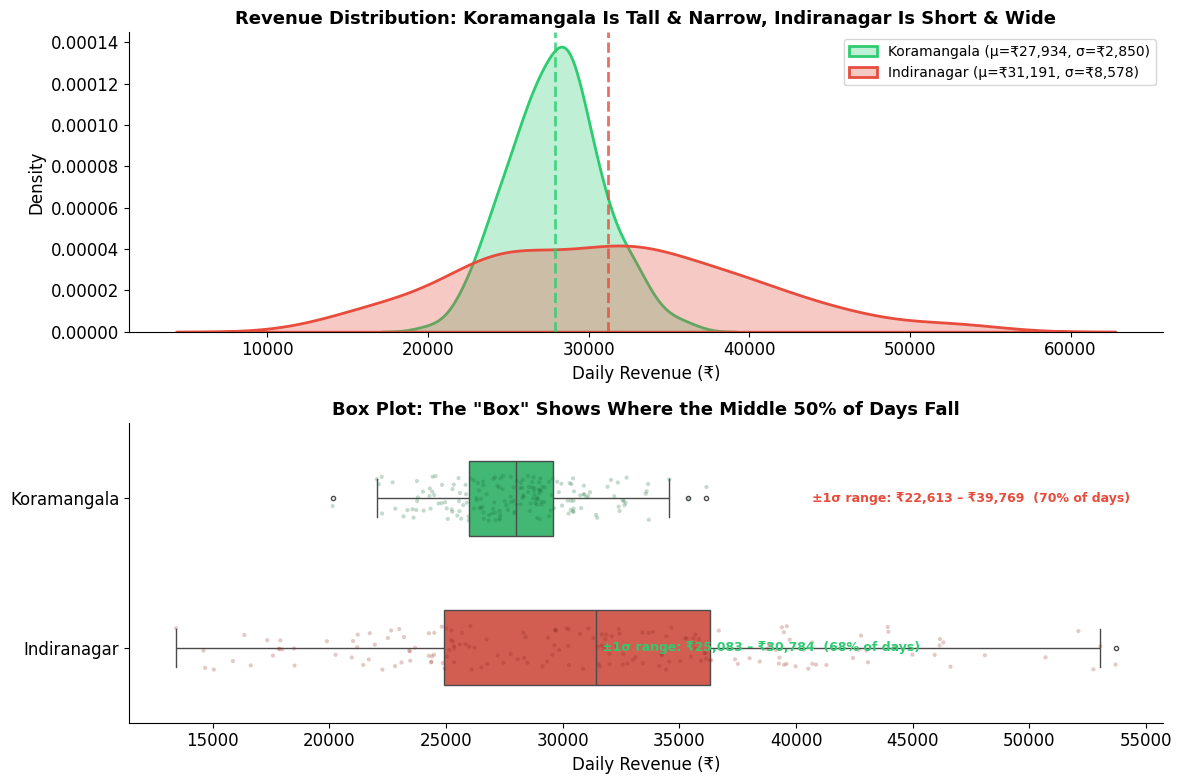

🔵 Top plot: The WIDER the curve, the more spread out (higher σ) the revenue is.
   Koramangala's curve is tall and narrow → consistent days.
   Indiranagar's curve is short and wide → wildly varying days.

📦 Bottom plot: Each dot is one day. The box shows the interquartile range (middle 50%).
   Notice how Indiranagar's dots stretch much further in both directions!


In [39]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8))

# --- Plot 1: Overlapping density curves ---
ax1 = axes[0]
for shop, color, data_col in [('Koramangala', '#2ecc71', k_rev), ('Indiranagar', '#e74c3c', i_rev)]:
    mean_val = data_col.mean()
    std_val = data_col.std()
    ax1.axvline(mean_val, color=color, linewidth=2, linestyle='--', alpha=0.8)
    sns.kdeplot(data_col, ax=ax1, color=color, fill=True, alpha=0.3, linewidth=2, label=f'{shop} (μ=₹{mean_val:,.0f}, σ=₹{std_val:,.0f})')

ax1.set_xlabel('Daily Revenue (₹)')
ax1.set_ylabel('Density')
ax1.set_title('Revenue Distribution: Koramangala Is Tall & Narrow, Indiranagar Is Short & Wide',
              fontsize=13, fontweight='bold')
ax1.legend(fontsize=10)

# --- Plot 2: Box + strip plot for direct comparison ---
ax2 = axes[1]
revenue_data = df[['shop', 'daily_revenue_inr']].copy()
sns.boxplot(data=revenue_data, x='daily_revenue_inr', y='shop', ax=ax2,
            palette={'Koramangala': '#2ecc71', 'Indiranagar': '#e74c3c'},
            width=0.5, fliersize=3)
sns.stripplot(data=revenue_data, x='daily_revenue_inr', y='shop', ax=ax2,
              palette={'Koramangala': '#196F3D', 'Indiranagar': '#922B21'},
              alpha=0.25, size=3, jitter=0.15)

# Add mean ± 1σ annotations
for idx, (shop, color, data_col) in enumerate([('Indiranagar', '#e74c3c', i_rev), ('Koramangala', '#2ecc71', k_rev)]):
    mean_val = data_col.mean()
    std_val = data_col.std()
    within = ((data_col >= mean_val - std_val) & (data_col <= mean_val + std_val)).sum()
    pct = within / len(data_col) * 100
    ax2.annotate(f'±1σ range: ₹{mean_val - std_val:,.0f} – ₹{mean_val + std_val:,.0f}  ({pct:.0f}% of days)',
                 xy=(mean_val + std_val, idx), fontsize=9, fontweight='bold',
                 xytext=(15, 0), textcoords='offset points', va='center',
                 color=color)

ax2.set_xlabel('Daily Revenue (₹)')
ax2.set_ylabel('')
ax2.set_title('Box Plot: The "Box" Shows Where the Middle 50% of Days Fall',
              fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

print("🔵 Top plot: The WIDER the curve, the more spread out (higher σ) the revenue is.")
print("   Koramangala's curve is tall and narrow → consistent days.")
print("   Indiranagar's curve is short and wide → wildly varying days.")
print("\n📦 Bottom plot: Each dot is one day. The box shows the interquartile range (middle 50%).")
print("   Notice how Indiranagar's dots stretch much further in both directions!")

### 🧠 Why Does This Matter for Machine Learning?

This isn't just business math. Variance and standard deviation are **everywhere** in ML:

| ML Concept | Why Variance Matters |
|:--|:--|
| **Feature Selection** | A feature with zero variance (e.g., a column that's always "India") carries no information. Drop it. |
| **Feature Scaling** | StandardScaler divides by σ to put all features on the same scale. Without this, features with large values dominate. |
| **Overfitting** | High variance in model predictions = overfitting. The model is too sensitive to training data. |
| **PCA** | Principal Component Analysis finds directions of maximum variance — because that's where the information is. |
| **Regularization** | Controls how much variance (complexity) the model is allowed to learn. |

**The core principle:** *Variance = Information. No variance = Nothing to learn from.*

## Chapter 6: A Subtle But Important Detail — Sample vs Population

### The Scenario

Priya comes back and says:

> *"Actually, both shops have been open for 3 years. You only have 6 months of data. Can you still make conclusions about the shops in general?"*

This is the **sample vs population** problem:
- **Population** = ALL the data that could ever exist (every day the shop has been or will be open)
- **Sample** = The subset we actually have (our 180 days)

When we compute mean and variance on a sample, there's a subtle bias...

In [40]:
# The issue: sample variance UNDERESTIMATES population variance
# Let's demonstrate this with a simulation

np.random.seed(123)

# Pretend this is the TRUE population (3 years = ~1095 days of Koramangala)
population = np.random.normal(loc=28000, scale=3000, size=1095)
true_variance = population.var()  # divide by N (population)

print(f"TRUE population variance (if we had ALL the data): {true_variance:,.0f}")
print(f"\nNow let's see what happens when we take samples of 180 days...\n")

# Take many samples and compute variance both ways
n_experiments = 1000
sample_size = 180

var_with_n = []      # divide by n (population formula on sample)
var_with_n_minus_1 = []  # divide by n-1 (Bessel's correction)

for _ in range(n_experiments):
    sample = np.random.choice(population, size=sample_size, replace=False)
    var_with_n.append(sample.var())           # ddof=0 (divides by n)
    var_with_n_minus_1.append(sample.var(ddof=1))  # ddof=1 (divides by n-1)

print(f"Average of sample variances (÷ n):   {np.mean(var_with_n):>12,.0f}  ← systematically too LOW")
print(f"Average of sample variances (÷ n-1): {np.mean(var_with_n_minus_1):>12,.0f}  ← much closer to truth!")
print(f"True population variance:             {true_variance:>12,.0f}")
print(f"\n💡 Dividing by n-1 (Bessel's correction) compensates for the fact that")
print(f"   a sample tends to underestimate the true spread.")

TRUE population variance (if we had ALL the data): 8,920,834

Now let's see what happens when we take samples of 180 days...

Average of sample variances (÷ n):      8,880,878  ← systematically too LOW
Average of sample variances (÷ n-1):    8,930,492  ← much closer to truth!
True population variance:                8,920,834

💡 Dividing by n-1 (Bessel's correction) compensates for the fact that
   a sample tends to underestimate the true spread.


### Why Does Dividing by n Underestimate?

Here's the intuition (no proof needed!):

When you take a sample, the sample mean is **pulled toward** the data points in your sample. It's a little *too close* to them. So when you measure deviations from this sample mean, they look *smaller* than they really are.

Dividing by `n-1` instead of `n` inflates the estimate just enough to correct for this bias.

**The practical rule:**
- Got the ENTIRE dataset (population)? → Divide by `n` → `np.var(data)` or `data.var()`
- Got a SAMPLE and want to estimate the population? → Divide by `n-1` → `np.var(data, ddof=1)` or `data.var(ddof=1)`

In practice, when n is large (like our 180 days), the difference is tiny. But it matters a lot with small samples!

In [41]:
# Show the difference shrinks with sample size
print(f"{'Sample Size':>12} {'Var (÷n)':>12} {'Var (÷n-1)':>12} {'Difference':>12} {'% Difference':>14}")
print("-" * 68)

sample_full = df[df['shop']=='Koramangala']['daily_revenue_inr'].values
for n in [5, 10, 30, 50, 100, 180]:
    sub = sample_full[:n]
    v_n = sub.var()
    v_n1 = sub.var(ddof=1)
    diff = v_n1 - v_n
    pct = (diff / v_n) * 100
    print(f"{n:>12} {v_n:>12,.0f} {v_n1:>12,.0f} {diff:>12,.0f} {pct:>13.1f}%")

print(f"\n📉 With n=5, the correction adds 25%! With n=180, it's less than 1%.")
print("   Rule of thumb: Always use n-1 for samples. It never hurts, and it helps with small data.")

 Sample Size     Var (÷n)   Var (÷n-1)   Difference   % Difference
--------------------------------------------------------------------
           5    3,611,099    4,513,874      902,775          25.0%
          10    4,233,821    4,704,246      470,425          11.1%
          30    7,047,182    7,290,188      243,006           3.4%
          50    7,688,995    7,845,913      156,918           2.0%
         100    7,348,964    7,423,196       74,232           1.0%
         180    8,080,174    8,125,315       45,141           0.6%

📉 With n=5, the correction adds 25%! With n=180, it's less than 1%.
   Rule of thumb: Always use n-1 for samples. It never hurts, and it helps with small data.


## Chapter 7: The Big Picture — Data as Geometry 🌌

### Each Data Point Lives in Space

Now for the concept that ties everything together and opens the door to all of machine learning.

Remember our data has **4 features** per day: revenue, customers, order value, wait time. Each day is a data point with 4 numbers.

Here's the key insight: **each data point is a point in 4-dimensional space**, where each feature is one axis (one dimension).

We can't visualize 4D, so let's start with 2 features to build intuition.

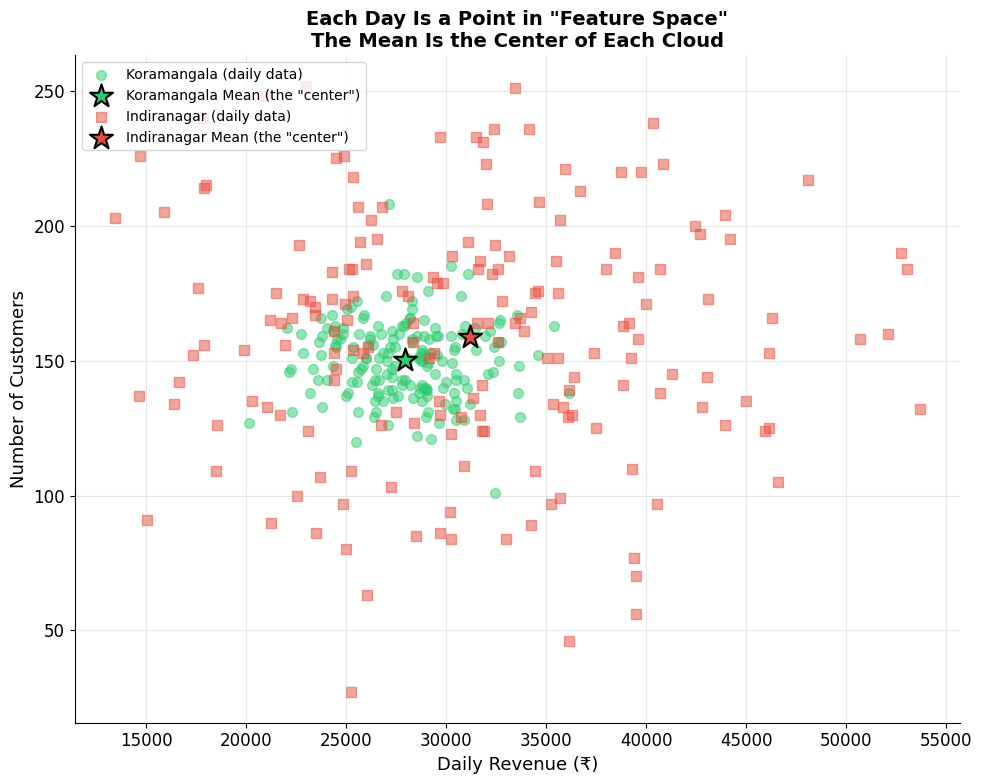

⭐ The stars are the MEANS — the geometric center of each cloud.

🔑 Key observations:
   1. Each point = one day in 2D 'feature space'
   2. The mean = the CENTER of the cloud (its 'address' in space)
   3. Koramangala's cloud is TIGHT (low variance) — points cluster near the mean
   4. Indiranagar's cloud is SPREAD OUT (high variance) — points scatter far from the mean

   The variance tells us the SIZE of each cloud.
   The mean tells us the LOCATION of each cloud.


In [42]:
# Pick 2 features: revenue and customers
fig, ax = plt.subplots(figsize=(10, 8))

for shop, color, marker in [('Koramangala', '#2ecc71', 'o'), ('Indiranagar', '#e74c3c', 's')]:
    data = df[df['shop'] == shop]
    ax.scatter(data['daily_revenue_inr'], data['customers'],
               alpha=0.5, s=50, color=color, marker=marker, label=f'{shop} (daily data)')

    # Plot the mean as a big star
    mean_x = data['daily_revenue_inr'].mean()
    mean_y = data['customers'].mean()
    ax.scatter(mean_x, mean_y, s=300, color=color, marker='*',
               edgecolors='black', linewidth=1.5, zorder=5,
               label=f'{shop} Mean (the "center")')

ax.set_xlabel('Daily Revenue (₹)', fontsize=13)
ax.set_ylabel('Number of Customers', fontsize=13)
ax.set_title('Each Day Is a Point in "Feature Space"\nThe Mean Is the Center of Each Cloud',
             fontsize=14, fontweight='bold')
ax.legend(fontsize=10, loc='upper left')
ax.grid(True, alpha=0.3)

plt.tight_layout()

plt.show()

print("⭐ The stars are the MEANS — the geometric center of each cloud.")
print("\n🔑 Key observations:")
print("   1. Each point = one day in 2D 'feature space'")
print("   2. The mean = the CENTER of the cloud (its 'address' in space)")
print("   3. Koramangala's cloud is TIGHT (low variance) — points cluster near the mean")
print("   4. Indiranagar's cloud is SPREAD OUT (high variance) — points scatter far from the mean")
print("\n   The variance tells us the SIZE of each cloud.")
print("   The mean tells us the LOCATION of each cloud.")

### Variance = The Size of the Cloud

In geometry, variance measures how **spread out** the cloud of points is along each axis. High variance along an axis means the cloud is stretched out in that direction.

Let's visualize this with ellipses showing ±1σ and ±2σ regions.

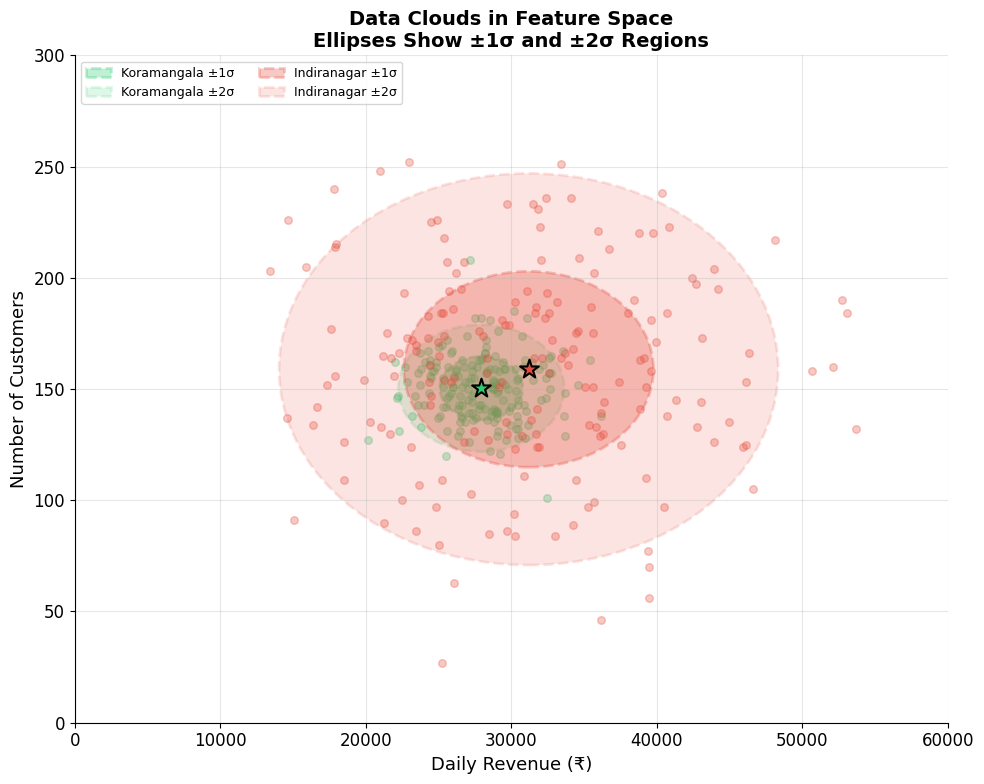

🟢 Koramangala: Tight cloud → low variance → predictable
🔴 Indiranagar: Sprawling cloud → high variance → unpredictable

🧠 In ML, algorithms learn by finding PATTERNS in these clouds.
   Tighter clouds = clearer patterns = easier for models to learn.


In [43]:
fig, ax = plt.subplots(figsize=(10, 8))

for shop, color in [('Koramangala', '#2ecc71'), ('Indiranagar', '#e74c3c')]:
    data = df[df['shop'] == shop]
    x = data['daily_revenue_inr']
    y = data['customers']

    ax.scatter(x, y, alpha=0.3, s=30, color=color)

    # Mean
    mx, my = x.mean(), y.mean()
    ax.scatter(mx, my, s=200, color=color, marker='*', edgecolors='black', linewidth=1.5, zorder=5)

    # Draw ellipses for 1σ and 2σ
    for n_std, alpha_val in [(1, 0.3), (2, 0.15)]:
        ellipse = Ellipse(xy=(mx, my),
                          width=2 * n_std * x.std(),
                          height=2 * n_std * y.std(),
                          facecolor=color, alpha=alpha_val,
                          edgecolor=color, linewidth=2, linestyle='--',
                          label=f'{shop} ±{n_std}σ')
        ax.add_patch(ellipse)

ax.set_xlabel('Daily Revenue (₹)', fontsize=13)
ax.set_ylabel('Number of Customers', fontsize=13)
ax.set_title('Data Clouds in Feature Space\nEllipses Show ±1σ and ±2σ Regions',
             fontsize=14, fontweight='bold')
ax.legend(fontsize=9, loc='upper left', ncol=2)
ax.grid(True, alpha=0.3)
ax.set_xlim(0, 60000)
ax.set_ylim(0, 300)

plt.tight_layout()

plt.show()

print("🟢 Koramangala: Tight cloud → low variance → predictable")
print("🔴 Indiranagar: Sprawling cloud → high variance → unpredictable")
print("\n🧠 In ML, algorithms learn by finding PATTERNS in these clouds.")
print("   Tighter clouds = clearer patterns = easier for models to learn.")

### Scaling Up: Every Feature Is a Dimension

Our data has 4 features, so each day actually lives in **4-dimensional space**. We can't draw 4D, but the concepts are the same:

| Concept | 2D Analogy | n-Dimensional Reality |
|:--|:--|:--|
| **Data point** | A dot on a 2D plot | A point in n-dimensional space |
| **Feature** | One axis (x or y) | One of n axes/dimensions |
| **Mean** | Center of the 2D cloud | Center of the n-D cloud |
| **Variance** | Width of the cloud along one axis | Spread along one dimension |
| **Dataset** | A 2D scatter plot | A cloud of points in n-D space |

This geometric view is **the foundation of ML**. Algorithms like KNN find nearby points in this space. SVMs find boundaries between clouds. PCA rotates the space to find the dimensions with the most variance (information).

In [44]:
# Let's see the variance across ALL features for both shops
print("VARIANCE ACROSS ALL DIMENSIONS")
print("=" * 70)

for shop in ['Koramangala', 'Indiranagar']:
    data = df[df['shop'] == shop][features]
    print(f"\n  {shop}:")
    for feat in features:
        var = data[feat].var()
        std = data[feat].std()
        print(f"    {feat:25s}  σ² = {var:>15,.1f}   σ = {std:>10,.1f}")

print("\n" + "=" * 70)
print("\n🔑 In EVERY dimension, Indiranagar has higher variance.")
print("   Its cloud is bigger in every direction — it's more unpredictable across the board.")

VARIANCE ACROSS ALL DIMENSIONS

  Koramangala:
    daily_revenue_inr          σ² =     8,125,314.6   σ =    2,850.5
    customers                  σ² =           203.5   σ =       14.3
    avg_order_value            σ² =           150.8   σ =       12.3
    avg_wait_time_min          σ² =             1.1   σ =        1.0

  Indiranagar:
    daily_revenue_inr          σ² =    73,578,756.8   σ =    8,577.8
    customers                  σ² =         1,937.7   σ =       44.0
    avg_order_value            σ² =           981.2   σ =       31.3
    avg_wait_time_min          σ² =             8.6   σ =        2.9


🔑 In EVERY dimension, Indiranagar has higher variance.
   Its cloud is bigger in every direction — it's more unpredictable across the board.


## Chapter 8: The Verdict — Making the Decision 🏆

Now we have all the tools. Let's put together our recommendation for Priya.

In [45]:
# Comprehensive comparison
print("╔" + "═" * 64 + "╗")
print("║" + "  BEANSCENE ANALYTICS REPORT: FLAGSHIP EXPANSION DECISION".center(64) + "║")
print("╠" + "═" * 64 + "╣")
print("║" + "".center(64) + "║")

for feat, label, unit in [
    ('daily_revenue_inr', 'Daily Revenue', '₹'),
    ('customers', 'Customers/Day', ''),
    ('avg_order_value', 'Avg Order Value', '₹'),
    ('avg_wait_time_min', 'Avg Wait Time', 'min'),
]:
    k = df[df['shop']=='Koramangala'][feat]
    i = df[df['shop']=='Indiranagar'][feat]
    print(f"║  {label:25s}{'Koramangala':>15}  {'Indiranagar':>15}   ║")
    print(f"║  {'  Mean':25s}{unit}{k.mean():>13,.1f}  {unit}{i.mean():>13,.1f}   ║")
    print(f"║  {'  Std Dev':25s}{unit}{k.std():>13,.1f}  {unit}{i.std():>13,.1f}   ║")
    print(f"║  {'  CV (Std/Mean)':25s}{k.std()/k.mean():>14.1%}  {i.std()/i.mean():>14.1%}   ║")
    print("║" + "".center(64) + "║")

print("╠" + "═" * 64 + "╣")
print("║" + "  RECOMMENDATION".center(64) + "║")
print("║" + "".center(64) + "║")
print("║" + "  → Koramangala: Lower mean but HIGHLY CONSISTENT.".ljust(64) + "║")
print("║" + "    Predictable revenue makes planning & staffing easy.".ljust(64) + "║")
print("║" + "".center(64) + "║")
print("║" + "  → Indiranagar: Slightly higher mean but VERY VOLATILE.".ljust(64) + "║")
print("║" + "    Some amazing days, but also some terrible ones.".ljust(64) + "║")
print("║" + "    Wait times are inconsistent (bad for customers).".ljust(64) + "║")
print("║" + "".center(64) + "║")
print("║" + "  📋 For a flagship store that needs reliable operations:".ljust(64) + "║")
print("║" + "     EXPAND KORAMANGALA ✅".center(64) + "║")
print("║" + "".center(64) + "║")
print("║" + "  📋 Investigate WHY Indiranagar is so volatile —".ljust(64) + "║")
print("║" + "     fix that first, then reconsider.".ljust(64) + "║")
print("╚" + "═" * 64 + "╝")

╔════════════════════════════════════════════════════════════════╗
║     BEANSCENE ANALYTICS REPORT: FLAGSHIP EXPANSION DECISION    ║
╠════════════════════════════════════════════════════════════════╣
║                                                                ║
║  Daily Revenue                Koramangala      Indiranagar   ║
║    Mean                   ₹     27,933.6  ₹     31,190.9   ║
║    Std Dev                ₹      2,850.5  ₹      8,577.8   ║
║    CV (Std/Mean)                   10.2%           27.5%   ║
║                                                                ║
║  Customers/Day                Koramangala      Indiranagar   ║
║    Mean                           150.4          158.9   ║
║    Std Dev                         14.3           44.0   ║
║    CV (Std/Mean)                    9.5%           27.7%   ║
║                                                                ║
║  Avg Order Value              Koramangala      Indiranagar   ║
║    Mean                   ₹

## 📝 Summary: What We Learned (Cheat Sheet)

| Concept | What It Is | Coffee Shop Analogy | Why ML Cares |
|:--|:--|:--|:--|
| **Data as Geometry** | Each data point is a point in n-D space | Each day is a point in 4D (revenue, customers, order value, wait time) | All ML algorithms operate on this geometric view |
| **Mean (μ)** | The center of the data cloud | The "typical day" at each shop | Many algorithms start by finding the center (e.g., K-Means clustering) |
| **Variance (σ²)** | Average squared distance from the mean | How wildly daily revenue swings | High variance = more info but harder to predict; zero variance = useless feature |
| **Std Dev (σ)** | Square root of variance (human-readable) | "Revenue typically varies by ±₹X" | Used in StandardScaler, Z-scores, confidence intervals |
| **Sample vs Pop** | Are we measuring everything or a subset? | 6 months of data vs. all-time performance | Almost always working with samples in ML → use n-1 |

### The One-Line Version

> **The mean tells you WHERE the data lives. The variance tells you HOW MUCH it moves around. Together, they describe the shape of your data cloud — and that cloud is what ML algorithms learn from.**


---

### 🎯 Practice Exercises

1. **New Feature:** Priya now gives you data on `monthly_rent` for each shop. If rent is ₹200,000 for both shops every single month, what is the variance of this feature? Should an ML model use it? Why or why not?

2. **Coefficient of Variation:** We introduced CV (= σ/μ) in the report. Why might CV be better than raw standard deviation when comparing features with different scales (e.g., revenue in ₹ vs. wait time in minutes)?

3. **Geometric Thinking:** If you added a 5th feature (say, `customer_satisfaction_score`), what would change about the "space" each data point lives in? Would the mean still be a single point?

4. **Sample Size:** If Priya only had 2 weeks of data (14 days) instead of 6 months, how would that affect your confidence in the variance estimate? What would Bessel's correction do differently with n=14 vs n=180?

---
*Created for BeanScene Analytics Team | Data as Geometry Workshop*